<a href="https://colab.research.google.com/github/lewinskie254/stock-market-prediction/blob/main/predict_stock_prices.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [28]:
import numpy as np
import pandas as pd
import yfinance as yf
import torch
import torch.nn as nn
from tqdm.notebook import tqdm, trange
from statsmodels.tsa.statespace.sarimax import SARIMAX
import matplotlib.pyplot as plt

In [14]:
ticker = "AAPL"
stock = yf.Ticker(ticker)

# Get historical market data (e.g., past 1 year, daily interval)
hist = stock.history(period="1y", interval="1h")
print(hist.head())

# Get basic company info / metadata
info = stock.info
print(info.get("longName"), info.get("regularMarketPrice"))

# Get dividends and stock splits
dividends = stock.dividends
splits = stock.splits

                                 Open        High         Low       Close  \
Datetime                                                                    
2025-10-31 09:30:00-04:00  276.989990  277.320007  269.160004  270.380005   
2025-10-31 10:30:00-04:00  270.429993  271.559906  270.100098  271.299988   
2025-10-31 11:30:00-04:00  271.299896  272.858490  270.220001  272.434998   
2025-10-31 12:30:00-04:00  272.429993  273.170013  270.149994  270.348785   
2025-10-31 13:30:00-04:00  270.329987  272.059906  270.109985  271.809998   

                             Volume  Dividends  Stock Splits  
Datetime                                                      
2025-10-31 09:30:00-04:00  17228178        0.0           0.0  
2025-10-31 10:30:00-04:00   4595066        0.0           0.0  
2025-10-31 11:30:00-04:00   4301242        0.0           0.0  
2025-10-31 12:30:00-04:00   4005527        0.0           0.0  
2025-10-31 13:30:00-04:00   2396660        0.0           0.0  
Apple Inc. 344.63


In [15]:
hist

,Open,High,Low,Close,Volume,Dividends,Stock Splits
Datetime,,,,,,,
2025-10-31 09:30:00-04:00,276.989990,277.320007,269.160004,270.380005,17228178,0.0,0.0
2025-10-31 10:30:00-04:00,270.429993,271.559906,270.100098,271.299988,4595066,0.0,0.0
2025-10-31 11:30:00-04:00,271.299896,272.858490,270.220001,272.434998,4301242,0.0,0.0
2025-10-31 12:30:00-04:00,272.429993,273.170013,270.149994,270.348785,4005527,0.0,0.0
2025-10-31 13:30:00-04:00,270.329987,272.059906,270.109985,271.809998,2396660,0.0,0.0
...,...,...,...,...,...,...,...
2026-10-30 11:30:00-04:00,347.690002,347.880005,345.671112,347.500000,4661066,0.0,0.0
2026-10-30 12:30:00-04:00,347.494995,347.970001,346.244995,346.549988,4717714,0.0,0.0
2026-10-30 13:30:00-04:00,346.540009,346.689911,342.899994,343.134186,8261613,0.0,0.0


In [16]:
hist.isna().sum()

,0
Open,0
High,0
Low,0
Close,0
Volume,0
Dividends,0
Stock Splits,0


In [17]:
import warnings
warnings.filterwarnings('ignore')

def optimizeARIMA(df: pd.DataFrame, order: list):
    results = []

    for o in tqdm(order):
        model = SARIMAX(df, order=o)

        try:
            model_fit = model.fit()
            results.append([model_fit.aic, o])
        except Exception as e:
            print(f"Failed for order {o}: {e}")

    dataframe = pd.DataFrame(results)
    dataframe.columns = ["AIC", "order"]

    return dataframe.sort_values(by="AIC", ascending=True)

In [18]:
from itertools import product

ps = range(0, 7)
ds = range(0, 3)
qs = range(0, 7)

orders = product(ps, ds, qs)
orders = list(orders)

In [19]:
results_df = optimizeARIMA(hist["Close"], orders)

  0%|          | 0/147 [00:00<?, ?it/s]

In [20]:
results_df.head(10)

,AIC,order
131,24.000000,"(6, 0, 5)"
117,7101.876646,"(5, 1, 5)"
95,7103.177073,"(4, 1, 4)"
138,7103.460281,"(6, 1, 5)"
74,7103.668994,"(3, 1, 4)"
96,7104.223732,"(4, 1, 5)"
55,7104.970635,"(2, 1, 6)"
116,7105.177567,"(5, 1, 4)"
137,7105.639154,"(6, 1, 4)"
73,7109.779001,"(3, 1, 3)"


In [38]:
def trainARIMA(df: pd.Series,order: tuple,horizon: int,train_length: int,window: int) -> pd.DataFrame:

    total_length = train_length + horizon
    results = []

    for i in tqdm(range(train_length, total_length, window)):
        current_window = min(window, total_length - i)

        model = SARIMAX(df.iloc[:i], order=order)

        try:
            model_fit = model.fit()
            oos_pred = model_fit.forecast(current_window)
            results.extend(oos_pred.to_numpy())

        except Exception as e:
            print(f"Failed for order {order} route {i} : {e}")

    return pd.DataFrame(results, columns=["Predictions"])

In [39]:
model = SARIMAX(hist["Close"], order=(5, 1,5))
model_fit = model.fit()

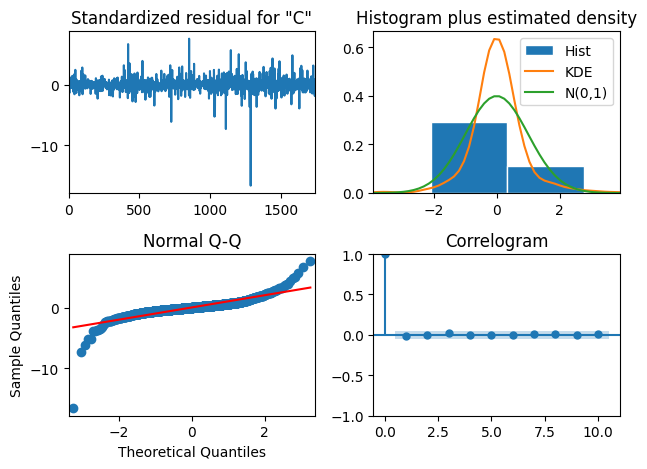

In [40]:
model_fit.plot_diagnostics()
plt.tight_layout()

In [44]:
horizon = 720
train_length = len(hist) - horizon
order = (4, 1, 4)
df = hist['Close']
df = df.reset_index(drop=True)
window = 1

In [45]:
preds = trainARIMA(df, order, horizon, train_length, window)

  0%|          | 0/720 [00:00<?, ?it/s]

Failed for order (4, 1, 4): LU decomposition error.
Failed for order (4, 1, 4): LU decomposition error.
Failed for order (4, 1, 4): LU decomposition error.


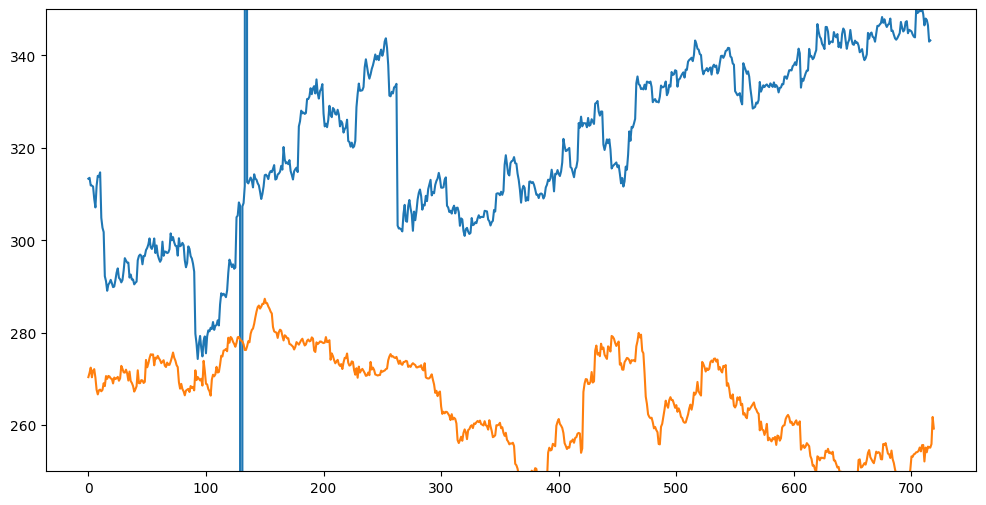

In [60]:
fig, ax = plt.subplots(figsize=(12, 6))
ax.plot(preds)
ax.plot(df[:720])
ax.set_ylim(250, 350)
plt.show()

<Axes: >

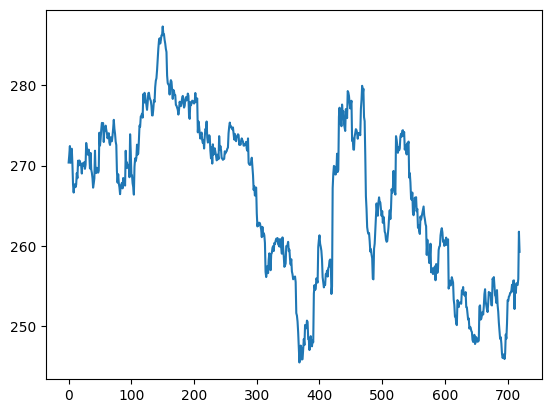

In [56]:
df[:720].plot()

In [57]:
len(preds)

717

In [58]:
len(df[:720])

720